# 2-D Partial Dependence Plot

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

A heatmap of a model's average prediction over a grid of two features, holding everything else at its observed values, with each feature's 1-D partial dependence along the margins. If the two effects simply add up, every row of the heatmap is the same left-to-right pattern shifted up or down. When the pattern changes shape from row to row, the features interact.

## When to use

- See how two features jointly drive a model's prediction
- Check whether an interaction the model may have learned is real and large
- Explain a nonlinear model (gradient boosting, random forest) to a technical audience

## Avoid when

- The two features are strongly correlated (the grid includes combinations that never occur)
- You need per-observation explanations (use ICE or SHAP dependence plots)
- The audience is non-technical (a 1-D effect plot is easier)

## Alternatives

- 1-D partial dependence with ICE lines
- SHAP dependence plot colored by the second feature

## Design tips

- Overlay the observed data points or a rug so readers can see where the grid is extrapolating
- Use one-hue sequential color with labelled contours
- Keep the margins on the same color/value scale as the heatmap

## Example

A gradient-boosting model predicting one-year disease progression in the real diabetes dataset that ships with scikit-learn (load_diabetes, 442 patients; features are standardized). Here the dependence is on body-mass index and log serum triglycerides (s5). The grid covers the 2nd–98th percentile of each feature.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import partial_dependence

### Data

In [2]:
diab = load_diabetes(as_frame=True)
X, y = diab.data, diab.target
model = GradientBoostingRegressor(n_estimators=250, max_depth=2, learning_rate=0.05,
                                  subsample=0.8, random_state=0).fit(X, y)
f1, f2 = "bmi", "s5"
# method="brute" averages real predictions; the fast "recursion" method for gradient boosting
# leaves out the initial (mean) prediction, so its values are offsets, not predicted progression.
grid = dict(grid_resolution=40, percentiles=(0.02, 0.98), kind="average", method="brute")
pd2 = partial_dependence(model, X, [f1, f2], **grid)
pd_x = partial_dependence(model, X, [f1], **grid)
pd_y = partial_dependence(model, X, [f2], **grid)
gx, gy = pd2["grid_values"]
Z = pd2["average"][0].T                      # rows = f2 (y), cols = f1 (x)
print(f"R² on training data: {model.score(X, y):.2f}; prediction range on grid: {Z.min():.0f}–{Z.max():.0f}")

R² on training data: 0.73; prediction range on grid: 88–247


### Plot

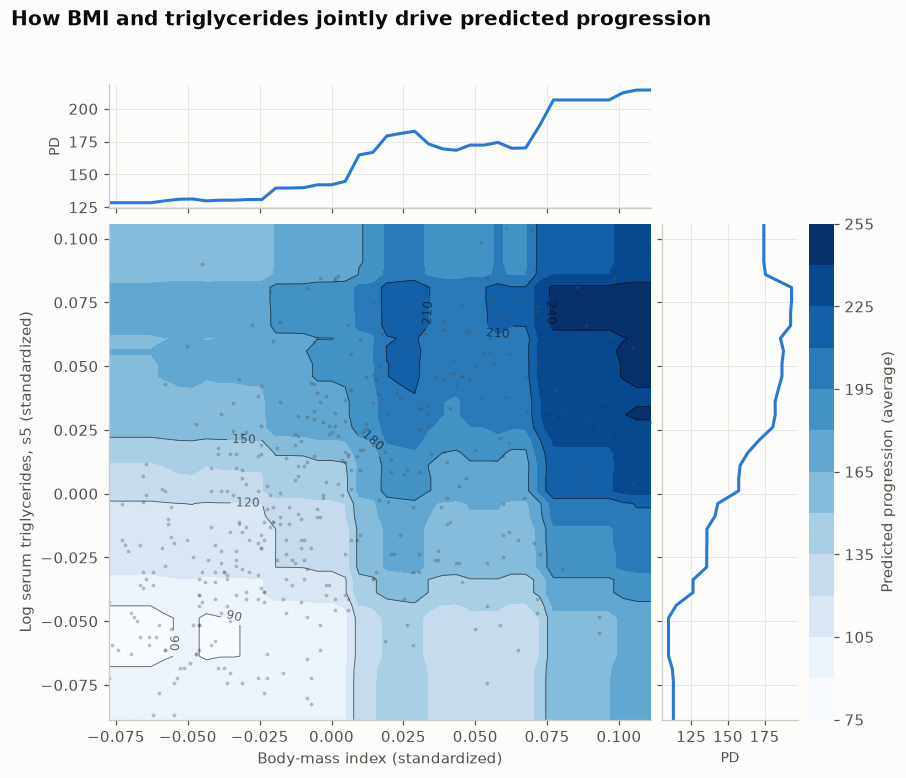

In [3]:
fig = plt.figure(figsize=(8.5, 7.5))
gs = fig.add_gridspec(2, 3, width_ratios=[4, 1, 0.18], height_ratios=[1, 4], hspace=0.05, wspace=0.05)
ax = fig.add_subplot(gs[1, 0])
top = fig.add_subplot(gs[0, 0], sharex=ax)
right = fig.add_subplot(gs[1, 1], sharey=ax)
cax = fig.add_subplot(gs[1, 2])
vmin, vmax = Z.min(), Z.max()
cf = ax.contourf(gx, gy, Z, levels=10, cmap=SEQ_CMAP, vmin=vmin, vmax=vmax)
cs = ax.contour(gx, gy, Z, levels=cf.levels[1:-1:2], colors="#0b0b0b", linewidths=0.6, alpha=0.6)
ax.clabel(cs, fmt="%.0f", fontsize=8)
ax.scatter(X[f1], X[f2], s=6, color="#52514e", alpha=0.35, linewidth=0)
ax.set_xlabel("Body-mass index (standardized)")
ax.set_ylabel("Log serum triglycerides, s5 (standardized)")
ax.set_xlim(gx[0], gx[-1])
ax.set_ylim(gy[0], gy[-1])
ax.grid(False)
top.plot(pd_x["grid_values"][0], pd_x["average"][0], color=PALETTE[0])
top.set_ylabel("PD", fontsize=9)
top.tick_params(labelbottom=False)
right.plot(pd_y["average"][0], pd_y["grid_values"][0], color=PALETTE[0])
right.set_xlabel("PD", fontsize=9)
right.tick_params(labelleft=False)
cb = fig.colorbar(cf, cax=cax)
cb.set_label("Predicted progression (average)")
cb.outline.set_visible(False)
fig.suptitle("How BMI and triglycerides jointly drive predicted progression",
             x=0.02, ha="left", fontsize=13, fontweight="bold", y=0.97)
plt.show()

## How to read it

Predicted progression rises toward the top-right, from about 90 in the lower-left corner to about 245 in the upper-right, so higher BMI and higher triglycerides both add risk. The two effects are similar in size: each margin spans roughly 85 points. The blocky contours come from the boosted trees' step functions. They form L-shapes rather than tilting or twisting, so the two effects are mostly additive with little interaction (an additive fit explains over 99% of the grid's variation). Gray dots are the real patients; sparse corners are extrapolation.

---
Standalone script: [`pdp_2d.py`](pdp_2d.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)